# Mean density plot as a function of radius and phase diagram

In [1]:
import yt
yt.set_log_level(50)
import unyt
from astropy.table import Table
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt

# Load the simulation data

In [25]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

target_sink=5

In [26]:
# Snapshot number
output=100

In [27]:
ds=yt.load(hf.info_file(output,df))

ad=ds.all_data(); # Load a data object that contains all data

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt


In [28]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

This output contains 660 black holes


In [29]:
# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting
print(sink_pos_ds)

[0.5041326  0.50041442 0.50459845] code_length


In [30]:
sp = ds.sphere(sink_pos_ds, ds.quan(5, 'kpc'))

cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

# Phase Diagram


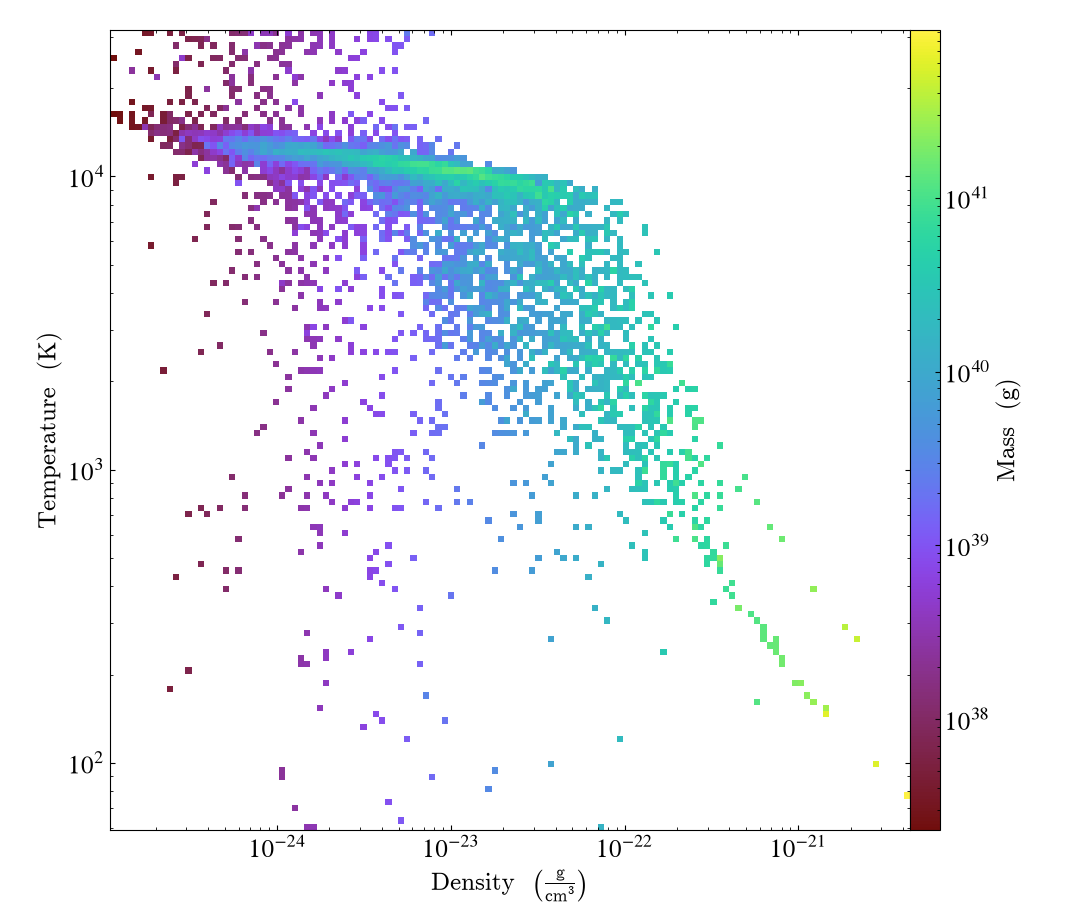

In [31]:
plot = yt.PhasePlot(
    cr, ("gas", "density"), ("gas", "temperature"), [("gas", "mass")], weight_field=None
)

# plot.save("fig/phase_1_1.png")
plot.show()

# Volume Weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt


Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt



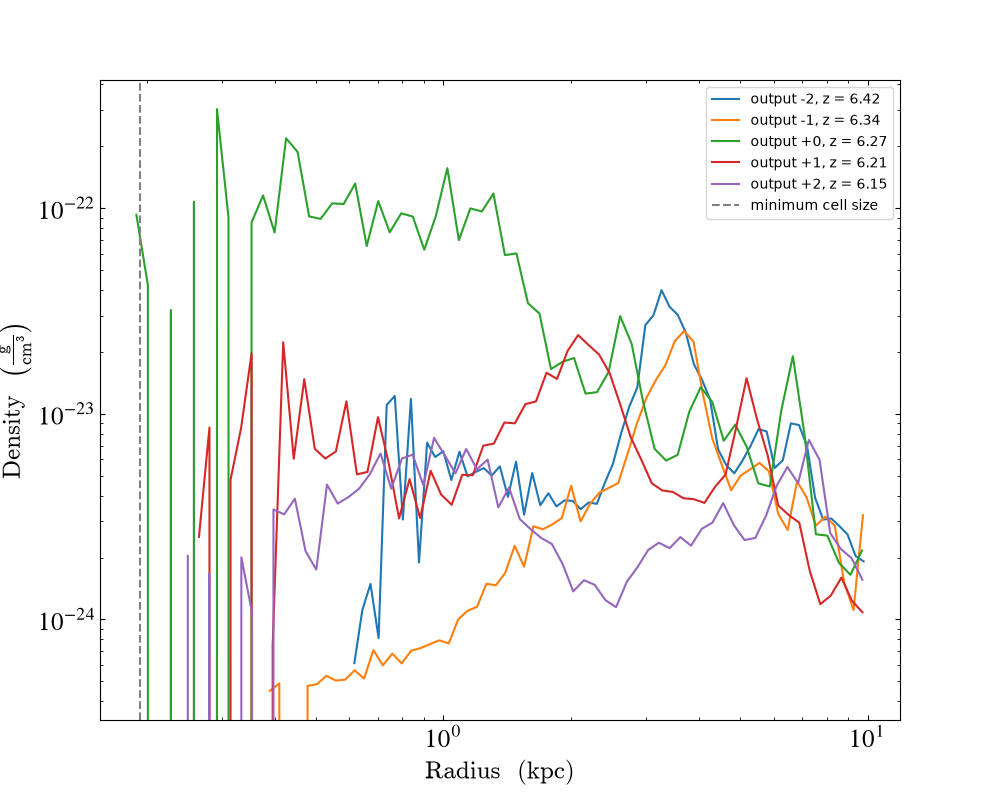

In [32]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "density")],
            weight_field= ("gas", "cell_volume"),
            units={("index", "radius"): "kpc"}
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.render()

ax = plot.plots[('gas', 'density')].axes
ax.axvline(0.193, ls='--', c='grey', label='minimum cell size')
ax.legend()

plot.show()
# plot.save("fig/radial_profile/most_massive_volume_2.png")

# Mass weighted radial density profile

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt



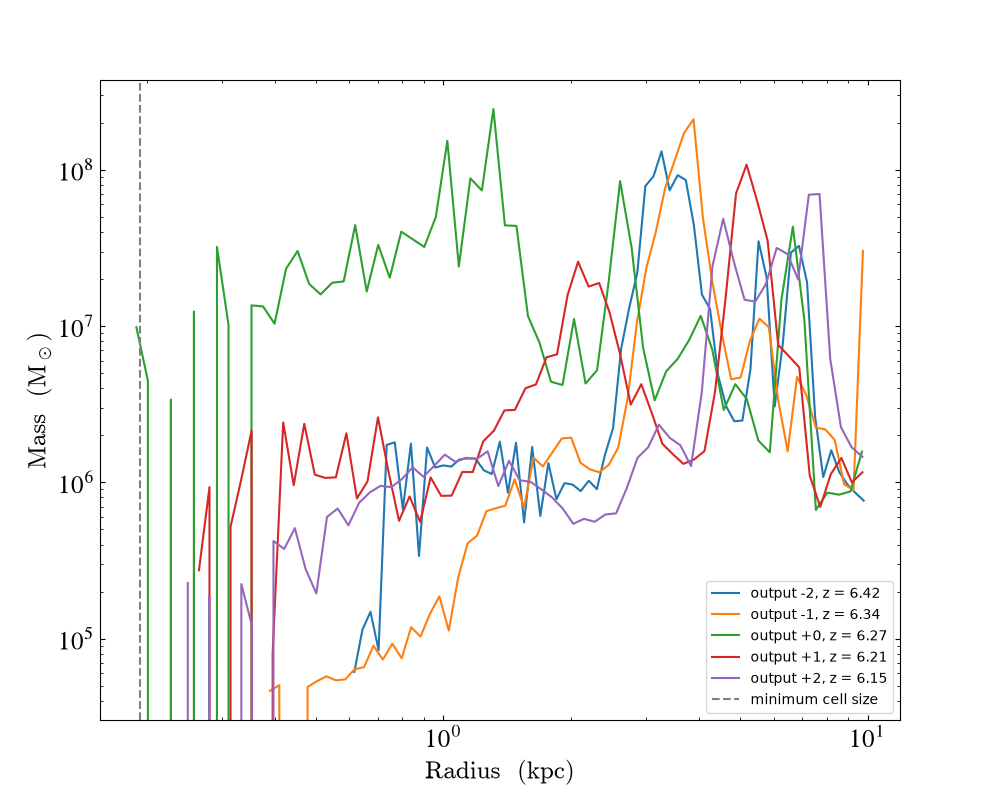

In [33]:
outputs = range(output - 2, output + 3)

profiles, labels = [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))
    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= ("gas", "mass"),
            units={("index", "radius"): "kpc"}
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')
plot.render()

ax = plot.plots[('gas', 'mass')].axes
ax.axvline(0.193, ls='--', c='grey', label='minimum cell size')
ax.legend()

plot.show()
# plot.save("fig/radial_profile/most_massive_mass_2.png")

# Accumulated Mass

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt



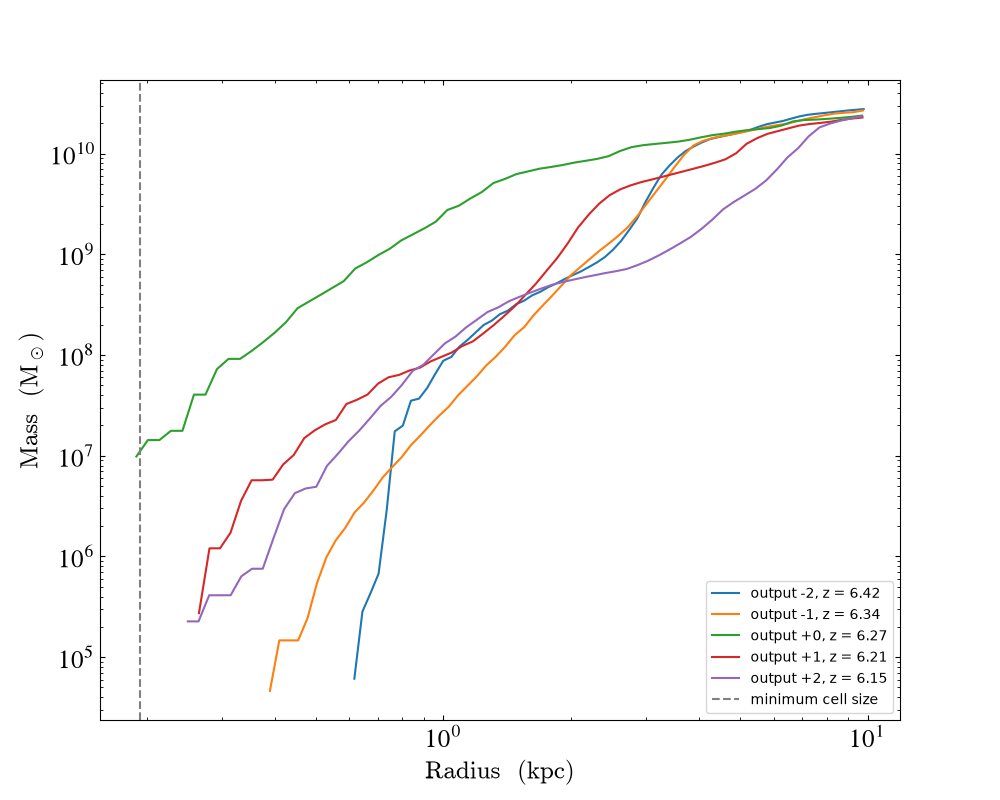

In [40]:
outputs = range(output - 2, output + 3)

profiles, profiles_all, labels = [], [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))

    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

    sink_pos=t[t['sink_id']==target_sink]['x','y','z']
    sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length')

    sp = ds.sphere(sink_pos_ds, ds.quan(10, 'kpc'))

    cr = ds.cut_region(sp, ["obj['gas', 'temperature'] < 10 ** 4.5"])

    profiles.append(
        yt.create_profile(
            cr,
            [("index", "radius")],
            [("gas", "mass")],
            weight_field= None,
            units={("index", "radius"): "kpc"},
            accumulation=True
        )
    )

    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')
    
plot = yt.ProfilePlot.from_profiles(profiles, labels=labels)
plot.set_unit(('index', 'radius'), 'kpc')
plot.set_unit(('gas', 'mass'), 'Msun')
plot.render()

ax = plot.plots[('gas', 'mass')].axes
ax.axvline(0.193, ls='--', c='grey', label='minimum cell size')

ax.legend()

plot.show()
# plot.save('fig/radial_profile/most_massive_accumlation_2.png')

In [ ]:
outputs = range(output - 2, output + 3)
kw = dict(weight_field=None, accumulation=True,
          units={("index","radius"): "kpc"},
          extrema={("index","radius"): ((0.2,'kpc'), (10,'kpc'))},
          n_bins=64, logs={("index","radius"): True})

r_list, Mcold_list, Mall_list, labels = [], [], [], []
for out in outputs:
    ds = yt.load(hf.info_file(out, df))
    filename = f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    c = ds.arr(t[t['sink_id']==target_sink]['x','y','z'][0].as_void().tolist(), 'code_length')

    sp = ds.sphere(c, (10, 'kpc'))
    cr = sp.cut_region(["obj['gas','temperature'] < 10**4.5"])

    p_cold = yt.create_profile(cr, [("index","radius")], [("gas","mass")], **kw)
    p_all  = yt.create_profile(sp, [("index","radius")], [("gas","mass")], **kw)

    r_list.append(p_all.x.to('kpc').value)
    Mcold_list.append(p_cold[("gas","mass")].to('Msun').value)
    Mall_list.append(p_all[("gas","mass")].to('Msun').value)
    labels.append(f'output {out - output:+d}, z = {ds.current_redshift:.2f}')

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00101/info_00101.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00102/info_00102.txt


/tmp/ipykernel_2504366/2537103093.py:7: RuntimeWarning: invalid value encountered in divide
  ax[1].semilogx(r, np.where(Ma > 0, Mc / Ma, np.nan), '-', c=col)


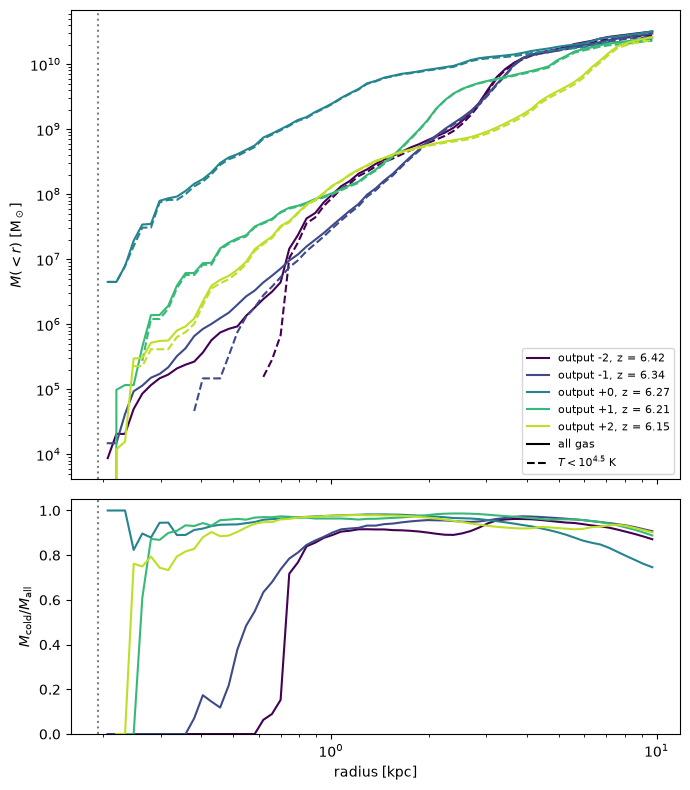

In [ ]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(7, 8), gridspec_kw={'height_ratios': [2, 1]})
cmap = plt.colormaps['viridis']
colors = cmap(np.linspace(0, 0.9, len(labels)))

for r, Mc, Ma, lab, col in zip(r_list, Mcold_list, Mall_list, labels, colors):
    ax[0].loglog(r, Ma, '-',  c=col, label=lab)
    ax[0].loglog(r, np.where(Mc > 0, Mc, np.nan), '--', c=col)
    ax[1].semilogx(r, np.where(Ma > 0, Mc / Ma, np.nan), '-', c=col)

for a in ax:
    a.axvline(0.193, ls=':', c='grey')
ax[0].set_ylabel(r'$M(<r)$ [M$_\odot$]')
ax[0].plot([], [], 'k-',  label='all gas')
ax[0].plot([], [], 'k--', label=r'$T < 10^{4.5}$ K')
ax[0].legend(fontsize=8)
ax[1].set_ylabel(r'$M_{\rm cold}/M_{\rm all}$')
ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel('radius [kpc]')
plt.tight_layout();

# Density vs time at a fixed radius

In [3]:
output = 100
target_sink=5

In [4]:
ts   = hf.SinkDataLoader(df, sinkid=target_sink)
time = Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt', format='ascii')
snap_t   = np.array([float(t) for t in time['time']])
snap_out = np.array([int(o) for o in time['output']])

mask = (snap_out >= output - 10) & (snap_out <= output + 10)

In [5]:
r0  = 1.0
dr  = 0.5

ds  = yt.load(hf.info_file(output, df))
filename = f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t   = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
sel = t[t['sink_id'] == target_sink]

c    = ds.arr(sel['x','y','z'][0].as_void().tolist(),    'code_length')
v_bh = ds.arr(sel['vx','vy','vz'][0].as_void().tolist(), 'code_velocity')

t_snap = snap_t[snap_out == output][0]
i = np.argmin(np.abs(ts.data['time'].to('Gyr').value - t_snap))

sp = ds.sphere(c, (10, 'kpc'))
sp.set_field_parameter('bulk_velocity', v_bh)

r  = sp['index','radius'].to('kpc').value
m  = sp['gas','mass'].to('Msun').value
vr = sp['gas','radial_velocity'].to('kpc/yr').value
s  = np.abs(r - r0) < dr/2

Min  = (m[s & (vr < 0)] * vr[s & (vr < 0)]).sum() / dr
Mout = (m[s & (vr > 0)] * vr[s & (vr > 0)]).sum() / dr
dx = sp['index', 'dx'].to('pc')

print('v_bh csv  :', v_bh.to('km/s'))
print('v_bh log  :', ts.data['vsink'][i])
print('pos  csv  :', c.to('pc'))
print('pos  log  :', ts.data['position'][i])
print('dx', dx.min())

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00100/info_00100.txt


v_bh csv  : [-110.97604701 -136.74670185 -619.2338357 ] km/s
v_bh log  : [-110.85626516 -136.74990955 -619.0708846 ]
pos  csv  : [50960667.09892572 50584810.88317159 51007757.33032471] pc
pos  log  : [50960667.0977078 50584810.8820513 51007757.3304612]
dx 192.80593605944532 pc


In [6]:
rho_rt, t_list = [], []
radii = [1.0, 2.0, 4.0, 8.0]
Min_list = {r0: [] for r0 in radii}
Mout_list = {r0: [] for r0 in radii}

for out, t_out in zip(snap_out[mask], snap_t[mask]):
    ds  = yt.load(hf.info_file(out, df))
    filename=f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    sel = t[t['sink_id'] == target_sink]
    c  = ds.arr(sel['x','y','z'][0].as_void().tolist(), 'code_length')
    v_bh = ds.arr(sel['vx','vy','vz'][0].as_void().tolist(), 'code_velocity')
    sp = ds.sphere(c, (10, 'kpc'))
    sp.set_field_parameter('bulk_velocity', v_bh)
    prof = yt.create_profile(sp, [("index","radius")], [("gas","density")],
                             weight_field=("gas","cell_volume"),
                             units={("index","radius"):"kpc"},
                             extrema={("index","radius"):(0.5, 10)})
    rho = prof[("gas","density")].to('g/cm**3').v
    rho[~prof.used] = np.nan
    rho_rt.append(rho)
    t_list.append(t_out)

    r  = sp['index','radius'].to('kpc').value
    m  = sp['gas','mass'].to('Msun').value
    vr = sp['gas','radial_velocity'].to('kpc/yr').value

    for r0 in radii:
        dr = 0.5
        s = np.abs(r - r0) < dr/2
        Min_list[r0].append((m[s & (vr < 0)] * vr[s & (vr < 0)]).sum() / dr)
        Mout_list[r0].append((m[s & (vr > 0)] * vr[s & (vr > 0)]).sum() / dr)

r_bins = prof.x.to('kpc').v
rho_rt = np.array(rho_rt)
t_list = np.array(t_list)
Min_list  = {k: np.array(v) for k, v in Min_list.items()}
Mout_list = {k: np.array(v) for k, v in Mout_list.items()};

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00090/info_00090.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00091/info_00091.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00092/info_00092.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00093/info_00093.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00094/info_00094.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00095/info_00095.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00096/info_00096.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00097/info_00097.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00098/info_00098.txt
Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00099/info_00099.txt
Opening /l

In [11]:
print(r_bins)

[0.51198028 0.53651495 0.56222535 0.58916782 0.6174014  0.64698796
 0.67799235 0.71048251 0.74452963 0.78020832 0.81759678 0.85677693
 0.89783464 0.94085988 0.98594694 1.03319463 1.08270647 1.13459098
 1.18896185 1.24593824 1.30564499 1.36821296 1.43377926 1.50248757
 1.57448846 1.64993971 1.72900667 1.81186261 1.8986891  1.98967641
 2.08502393 2.18494062 2.28964542 2.39936779 2.51434819 2.63483857
 2.76110299 2.89341814 3.03207398 3.17737436 3.32963771 3.48919768
 3.65640394 3.83162292 4.01523858 4.20765332 4.40928878 4.62058684
 4.84201054 5.07404511 5.31719904 5.57200518 5.83902191 6.11883439
 6.41205579 6.71932869 7.04132646 7.37875471 7.73235291 8.10289593
 8.49119578 8.8981034  9.32451049 9.77135149]


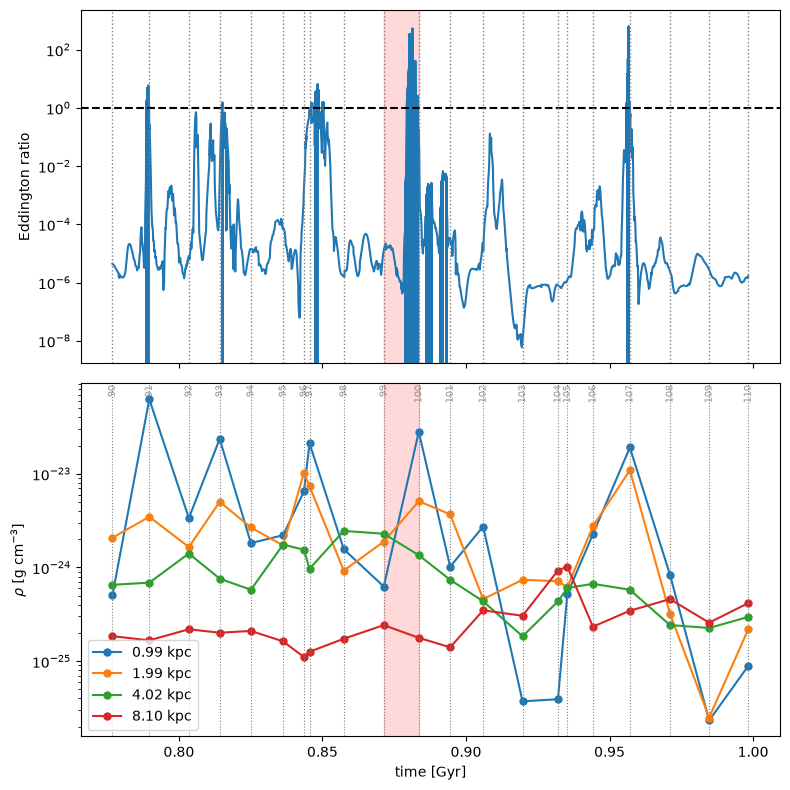

In [ ]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

output_labels = [str(o) for o in snap_out[mask]]

for r0 in [1.0, 2.0, 4.0, 8.0]:
    j = np.argmin(np.abs(r_bins - r0))
    axes[1].semilogy(t_list, rho_rt[:, j], 'o-', ms=5, label=f'{r_bins[j]:.2f} kpc')

t_before, t_target = snap_t[snap_out == output - 1][0], snap_t[snap_out == output][0]

axes[0].axvspan(t_before, t_target, color='r', alpha=0.15)
axes[1].axvspan(t_before, t_target, color='r', alpha=0.15)

ymin1, ymax1 = axes[1].get_ylim()
label_y = ymax1 * 0.95

for tt, label in zip(t_list, output_labels): 
    axes[0].axvline(tt, color='grey', ls=':', lw=1)
    axes[1].axvline(tt, color='grey', ls=':', lw=0.8)
    axes[1].text(tt, label_y, label, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)

axes[-1].set_ylabel(r'$\rho$ [g cm$^{-3}$]') 
axes[-1].set_xlabel('time [Gyr]')
axes[-1].legend()
plt.tight_layout()
# plt.savefig("fig/density_time_1");

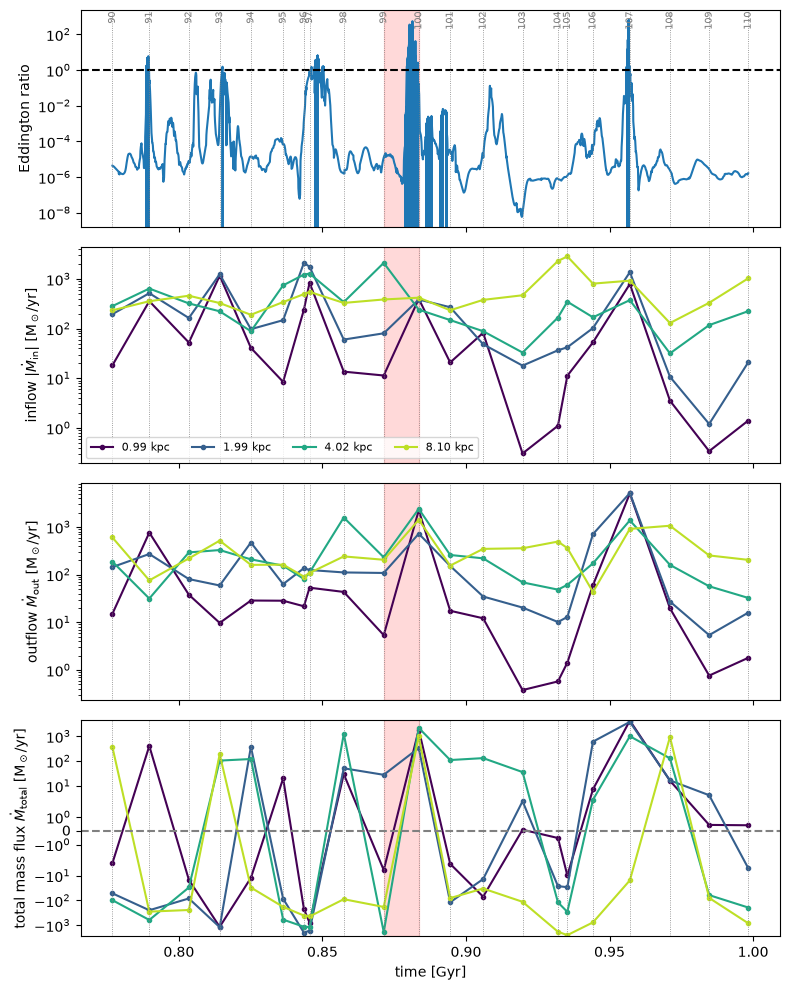

In [12]:
radii  = [1.0, 2.0, 4.0, 8.0]
cmap = plt.colormaps['viridis']
colors = cmap(np.linspace(0, 0.9, len(radii)))

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 10))
times = ts.data['time'].to('Gyr').value
m = (times > t_list[0]) & (times < t_list[-1])
axes[0].semilogy(times[m], (ts.data['dotMaccr']/ts.data['dotMedd'])[m])
axes[0].axhline(1, ls='--', c='k')
axes[0].set_ylabel('Eddington ratio')

for r0, col in zip(radii, colors):
    j = np.argmin(np.abs(r_bins - r0))
    axes[1].semilogy(t_list, -Min_list[r0], 'o-', c=col, ms=3, label=f'{r_bins[j]:.2f} kpc')
    axes[2].semilogy(t_list,  Mout_list[r0], 'o-', c=col, ms=3)
    axes[3].plot(t_list, Min_list[r0] + Mout_list[r0], 'o-', c=col, ms=3)
axes[1].set_ylabel(r'inflow $|\dot M_{\rm in}|$ [M$_\odot$/yr]')
axes[2].set_ylabel(r'outflow $\dot M_{\rm out}$ [M$_\odot$/yr]')
axes[3].set_ylabel(r'total mass flux $\dot M_{\rm total}$ [M$_\odot$/yr]')
axes[1].legend(fontsize=8, loc='lower left', ncol=4)

axes[3].axhline(0, c='grey', ls='--')
axes[3].set_yscale('symlog')


t_before = snap_t[snap_out == output - 1][0]
t_target = snap_t[snap_out == output][0]
for ax in axes:
    ax.axvspan(t_before, t_target, color='r', alpha=0.15)
    for tt in t_list:
        ax.axvline(tt, color='grey', ls=':', lw=0.6)

ymax = axes[0].get_ylim()[1]
for tt, out in zip(t_list, snap_out[mask]):
    axes[0].text(tt, ymax*0.8, str(out), color='grey', fontsize=7, rotation=90, va='top', ha='center')

axes[-1].set_xlabel('time [Gyr]')
plt.tight_layout()
# plt.savefig("fig/mass_flux_1")

# Filtering only cool gas from phase diagram